# Extended benchmark algorithm comparison

This notebook compares the scalable methods **Greedy, Heuristic, Uniform, and Random** on one-dimensional and two-dimensional spatial-field datasets generated with fixed cell-specific structural thresholds. Exhaustive is excluded because enumerating all allocations and adaptive trees is intended only for the compact benchmark.

Greedy allocates sensors using the average minimum pairwise error and then builds a local minimum-$P_{ijmn}$ tree. Uniform uses a near-uniform allocation and a seeded random pair-location tree. Random uses both a seeded random allocation and tree. Every completed tree is evaluated with the full $P/Q$ branch model under equal field priors.

In [1]:
# Resolve the project whether Jupyter starts here or from the repository root.
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

from analysis import run_analysis
from figures import save_figures, summary_markdown

## Experimental settings

`test` mode selects **180 cases per spatial dimension**, balanced as 60 Gaussian, 60 quadratic, and 60 sinusoidal cases. For the current extended design, this includes 90 cases with $(K,M)=(3,3)$ and 90 with $(K,M)=(3,4)$ in each dimension. `full` mode uses all 2,700 cases in each dimension.

The time limit applies independently to each method-budget evaluation, and checkpoint reuse supports interrupted runs.

In [2]:
# Use "full" for the complete study after confirming the test run.
RUN_MODE = "test"
RESUME = True
TIME_LIMIT_SECONDS = 30.0

# These controls apply only to the heuristic method.
BEAM_WIDTH = 3
MAX_ITERATIONS = 30

# This notebook is intentionally tied to the extended datasets.
STUDY = "extended"

## Run the matched comparison

Greedy, Heuristic, Uniform, and Random are evaluated on identical selected case-budget combinations. Results are checkpointed after every method-budget evaluation, and aggregation uses only combinations completed by all four methods.

In [3]:
# Run or resume the extended comparison with the settings above.
analysis = run_analysis(
    project=PROJECT,
    study=STUDY,
    mode=RUN_MODE,
    resume=RESUME,
    exact_k_max=4,  # Accepted by the shared runner; Exhaustive is not used here.
    time_limit=TIME_LIMIT_SECONDS,
    beam_width=BEAM_WIDTH,
    max_iterations=MAX_ITERATIONS,
)

# Confirm that this notebook used both extended datasets and the four scalable methods.
expected_datasets = {"benchmark_1d", "benchmark_2d"}
expected_methods = {"Greedy", "Heuristic", "Uniform", "Random"}
observed_datasets = {row["dataset"] for row in analysis["rows"]}
observed_methods = {row["method"] for row in analysis["rows"]}
assert observed_datasets == expected_datasets
assert observed_methods == expected_methods

case_counts = {
    dimension: len({
        (row["dataset"], row["case"])
        for row in analysis["rows"]
        if int(row["dimension"]) == dimension
    })
    for dimension in (1, 2)
}
if RUN_MODE == "test":
    assert min(case_counts.values()) >= 180

print("Verified datasets:", sorted(observed_datasets))
print("Verified methods:", sorted(observed_methods))
print("Unique cases by dimension:", case_counts)
print("Results directory:", analysis["output"])

extended/test: 360 cases, methods: Greedy, Heuristic, Uniform, Random
1/360 cases; 0 cached method results
10/360 cases; 0 cached method results
20/360 cases; 0 cached method results
30/360 cases; 0 cached method results
40/360 cases; 0 cached method results
50/360 cases; 0 cached method results
60/360 cases; 0 cached method results
70/360 cases; 0 cached method results
80/360 cases; 0 cached method results
90/360 cases; 0 cached method results
100/360 cases; 0 cached method results
110/360 cases; 0 cached method results
120/360 cases; 0 cached method results
130/360 cases; 0 cached method results
140/360 cases; 0 cached method results
150/360 cases; 0 cached method results
160/360 cases; 0 cached method results
170/360 cases; 0 cached method results
180/360 cases; 0 cached method results
190/360 cases; 0 cached method results
200/360 cases; 0 cached method results
210/360 cases; 0 cached method results
220/360 cases; 0 cached method results
230/360 cases; 0 cached method results
240/3

## Completion and matched summary

The completion counts are shown before aggregation. The summary table reports matched sample sizes, mean budget fraction, mean error probability, and mean runtime.

In [4]:
# Report method completion before displaying aggregate values.
from collections import Counter

completion = Counter((row["method"], row["status"]) for row in analysis["rows"])
print("Method-status counts:", completion)
display(Markdown(summary_markdown(analysis["summary"])))

Method-status counts: Counter({('Greedy', 'ok'): 1412, ('Heuristic', 'ok'): 1412, ('Uniform', 'ok'): 1412, ('Random', 'ok'): 1412})


| Dimension | Budget | Method | Cases | Mean Error Probability | Mean Time (s) | Mean Gap |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 1 | Greedy | 180 | 0.32593 | 0.0002 | — |
| One-dimensional | 1 | Heuristic | 180 | 0.32388 | 0.0004 | — |
| One-dimensional | 1 | Random | 180 | 0.58488 | 0.0001 | — |
| One-dimensional | 1 | Uniform | 180 | 0.58550 | 0.0001 | — |
| One-dimensional | 2 | Greedy | 180 | 0.19521 | 0.0003 | — |
| One-dimensional | 2 | Heuristic | 180 | 0.18730 | 0.0006 | — |
| One-dimensional | 2 | Random | 180 | 0.52412 | 0.0001 | — |
| One-dimensional | 2 | Uniform | 180 | 0.50716 | 0.0001 | — |
| One-dimensional | 3 | Greedy | 179 | 0.12340 | 0.0004 | — |
| One-dimensional | 3 | Heuristic | 179 | 0.09823 | 0.0007 | — |
| One-dimensional | 3 | Random | 179 | 0.44511 | 0.0001 | — |
| One-dimensional | 3 | Uniform | 179 | 0.43296 | 0.0001 | — |
| One-dimensional | 4 | Greedy | 165 | 0.08942 | 0.0005 | — |
| One-dimensional | 4 | Heuristic | 165 | 0.05703 | 0.0009 | — |
| One-dimensional | 4 | Random | 165 | 0.39123 | 0.0001 | — |
| One-dimensional | 4 | Uniform | 165 | 0.38382 | 0.0001 | — |
| Two-dimensional | 1 | Greedy | 180 | 0.34331 | 0.0002 | — |
| Two-dimensional | 1 | Heuristic | 180 | 0.34175 | 0.0004 | — |
| Two-dimensional | 1 | Random | 180 | 0.59442 | 0.0001 | — |
| Two-dimensional | 1 | Uniform | 180 | 0.59148 | 0.0001 | — |
| Two-dimensional | 2 | Greedy | 180 | 0.21241 | 0.0003 | — |
| Two-dimensional | 2 | Heuristic | 180 | 0.20907 | 0.0006 | — |
| Two-dimensional | 2 | Random | 180 | 0.52000 | 0.0001 | — |
| Two-dimensional | 2 | Uniform | 180 | 0.51411 | 0.0001 | — |
| Two-dimensional | 3 | Greedy | 180 | 0.13761 | 0.0004 | — |
| Two-dimensional | 3 | Heuristic | 180 | 0.11261 | 0.0007 | — |
| Two-dimensional | 3 | Random | 180 | 0.48454 | 0.0001 | — |
| Two-dimensional | 3 | Uniform | 180 | 0.45868 | 0.0001 | — |
| Two-dimensional | 4 | Greedy | 168 | 0.10396 | 0.0005 | — |
| Two-dimensional | 4 | Heuristic | 168 | 0.07398 | 0.0009 | — |
| Two-dimensional | 4 | Random | 168 | 0.43797 | 0.0001 | — |
| Two-dimensional | 4 | Uniform | 168 | 0.41314 | 0.0001 | — |

## Comparison figures

The primary figure plots **mean error probability versus mean budget fraction** for each method, with separate panels for the one-dimensional and two-dimensional datasets. The runtime figure is exported as a supporting comparison. Both figures use the matched samples summarized above.

### Error Probability

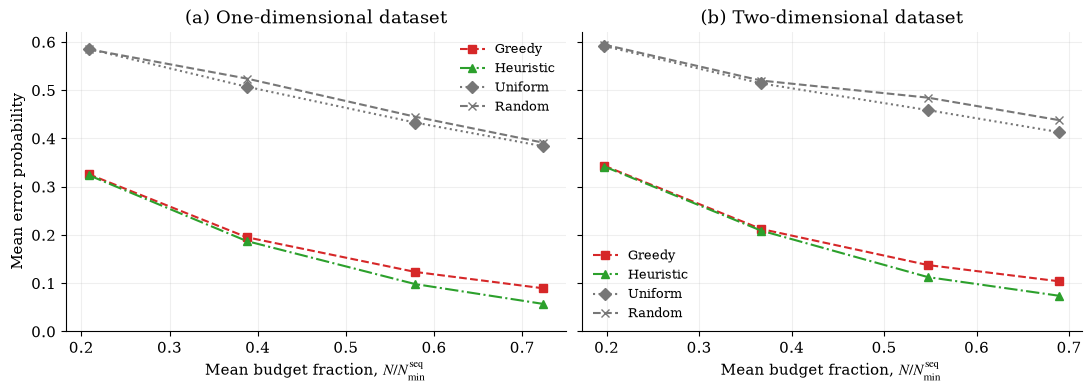

### Seconds

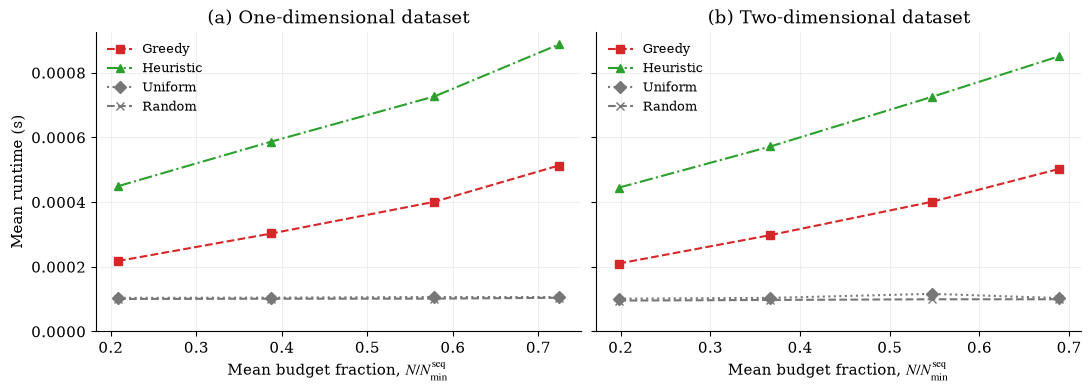

In [5]:
# Save publication-quality PDF and PNG versions, then display each figure.
if not analysis["summary"]:
    raise RuntimeError("No matched completed cases are available for plotting")

figures = save_figures(
    analysis["summary"],
    analysis["output"],
    include_exact=False,
)
for name, figure in figures.items():
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)